# R1 · TF-IDF + SVD

Training-only article TF-IDF → SVD (up to 128 dimensions) → window mean → concat with market and availability → MLP `(64, 32)`. No query, cross-attention, or gate. UP = USD/IDR rises (IDR depreciates).

Use the [shared split](../../SPLIT_PROTOCOL.md) and [ablation protocol](../../rules/ablation_protocol.md). Dependencies: NumPy, pandas, Matplotlib, scikit-learn. All run outputs stay in this notebook. R1 is a Level 2 benchmark, outside Level 3 by the declared study scope.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from sklearn.utils import check_random_state
from IPython import get_ipython

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "R1"
TEXT_WIDTH = 768
SVD_DIM = 128
SVD_SEED = 20261110
TFIDF_CONFIG = dict(lowercase=False, token_pattern=None, ngram_range=(1, 2), min_df=2,
                    max_df=1.0, max_features=20000, sublinear_tf=True, norm="l2", stop_words=None)
SVD_CONFIG = dict(algorithm="randomized", n_iter=7, n_oversamples=10, random_state=SVD_SEED)
TEXT_FEATURES = [f"svd_{i:03d}" if i < SVD_DIM else f"zero_text_{i:03d}" for i in range(TEXT_WIDTH)]
AVAIL_FEATURES = ["log1p_n_berita", "has_news"]
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 200
PATIENCE = 25
MLP_CONFIG = dict(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                  alpha=1e-3, batch_size=32, learning_rate_init=1e-3,
                  max_iter=1, shuffle=True, early_stopping=False)
RUN_FINAL_TEST = False  # Enable only after the experiment configurations are frozen.
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10       # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | seeds: {SEEDS} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

R1 | seeds: [42, 123, 2026] | final test enabled: False
Python 3.12.3 | pandas 3.0.5 | NumPy 2.5.3 | Matplotlib 3.11.2
scikit-learn 1.9.1


## Shared data

Reuse the exact dates, labels, eligible rows, retained articles, and window membership from Level 1. Static views use the same cleaned headline/lead spans as FinBERT. Vocabulary, IDF, SVD, and scalers never fit on validation/test. Current news timing remains date-delay sensitivity.

In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

contract = json.loads((BASE / "feature_contract.json").read_text())
MARKET_FEATURES = contract["market_features"]
FEATURES = MARKET_FEATURES.copy()
assert not set(FEATURES) & set(contract["target_and_diagnostic_columns_never_predictors"])
assert not set(FEATURES) & {"n_berita", "has_news", "y", "target_date", "next_jisdor"}
assert len(FEATURES) == len(set(FEATURES))
folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", *MARKET_FEATURES]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    assert np.isfinite(joined[MARKET_FEATURES].to_numpy(dtype=float)).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_validation_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    assert train.target_date.max() < val.Date.min()
    assert not set(train.Date) & set(val.Date)
    assert not seen_validation_dates & set(val.Date)
    seen_validation_dates.update(val.Date)
    for role, frame in [("train", train), ("validation", val)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})
final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")
print("Predictors:", ", ".join(FEATURES))
take_market_rows = take_rows

,run,role,n,first,last,down,up,news_days
0,fold_1,train,453,2021-09-29,2023-08-15,193,260,65
1,fold_1,validation,158,2023-08-21,2024-04-19,64,94,21
2,fold_2,train,612,2021-09-29,2024-04-19,257,355,86
3,fold_2,validation,159,2024-04-23,2024-12-12,78,81,32
4,fold_3,train,772,2021-09-29,2024-12-12,335,437,118
5,fold_3,validation,158,2024-12-16,2025-08-26,79,79,22


Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions
Predictors: log_return_t, return_lag1, return_lag2, return_lag3, return_lag5, volatility_5, volatility_20, ma_ratio_5, ma_ratio_20, momentum_5, momentum_10, rsi_14, input_gap_days, decision_weekday


## Fold-local representation

Use prepared lowercase static tokens with negation, entities, and numbers retained. TF-IDF uses unigram/bigram features, `min_df=2`, sublinear TF, and L2 normalization. Fit it on training articles only; fit SVD on those article vectors. Mean article vectors within each window, including zero/OOV vectors. Empty windows stay zero.

The classifier keeps a 768-wide text input, matching L1-d/R3: R1 uses up to 128 SVD coordinates plus fixed zero padding. The rank cap uses training data only. Report effective parameter counts; padding does not create additional information. The same input width and no learned adapter can be used for the remaining Level 2 representations.

In [3]:
article_path, window_path = BASE / "aligned_articles.jsonl", BASE / "news_windows.jsonl"
articles = pd.read_json(article_path, lines=True)
windows = pd.read_json(window_path, lines=True)
windows["Date"] = pd.to_datetime(windows.Date)
articles["anchor_date"] = pd.to_datetime(articles.anchor_date)
assert articles.article_id.is_unique and windows.Date.is_unique
assert np.array_equal(windows.Date.to_numpy(), daily.Date.to_numpy())
assert np.array_equal(windows.n_berita.to_numpy(), daily.n_berita.to_numpy())
assert not articles.known_temporal_contamination.any()
assert articles.text_tfidf.eq(articles.tokens_tfidf.map(" ".join)).all()
article_index = articles.set_index("article_id")
window_index = windows.set_index("Date")
for row in windows.itertuples():
    assert len(row.article_ids) == len(row.texts_tfidf) == row.n_berita
    for article_id, text in zip(row.article_ids, row.texts_tfidf):
        assert text == article_index.at[article_id, "text_tfidf"]
        assert row.Date == article_index.at[article_id, "anchor_date"]
FEATURES = [*MARKET_FEATURES, *TEXT_FEATURES, *AVAIL_FEATURES]
assert len(FEATURES) == len(set(FEATURES)) == 784

def array_sha256(value):
    return hashlib.sha256(np.ascontiguousarray(value).tobytes()).hexdigest()

def article_ids_for(dates):
    return sorted({article_id for date in dates for article_id in window_index.at[date, "article_ids"]})

class FoldTextRepresentation:
    def fit(self, training):
        started = time.perf_counter()
        self.training_dates = training.Date.tolist()
        self.training_ids = article_ids_for(self.training_dates)
        if len(self.training_ids) < 2:
            raise ValueError("At least two training articles are required for the declared TF-IDF/SVD baseline.")
        self.vectorizer = TfidfVectorizer(**TFIDF_CONFIG, tokenizer=str.split)
        matrix = self.vectorizer.fit_transform(article_index.loc[self.training_ids, "text_tfidf"])
        self.rank = min(SVD_DIM, matrix.shape[0] - 1, matrix.shape[1] - 1)
        if self.rank < 1:
            raise ValueError("Training vocabulary/matrix is too small for SVD.")
        self.svd = TruncatedSVD(n_components=self.rank, **SVD_CONFIG)
        with threadpool_limits(limits=1):
            self.svd.fit(matrix)
        self.vocabulary_sha = hashlib.sha256(json.dumps({term: int(index) for term, index in self.vectorizer.vocabulary_.items()}, sort_keys=True).encode()).hexdigest()
        self.idf_sha = array_sha256(self.vectorizer.idf_)
        self.components_sha = array_sha256(self.svd.components_)
        self.fit_seconds = time.perf_counter() - started
        self.coverage = {}
        self.fit_shape = matrix.shape
        self.fit_nnz = int(matrix.nnz)
        return self

    def transform(self, frame, role):
        ids = article_ids_for(frame.Date)
        if role in {"validation", "test"}:
            assert not set(ids) & set(self.training_ids)
        if ids:
            matrix = self.vectorizer.transform(article_index.loc[ids, "text_tfidf"])
            with threadpool_limits(limits=1):
                dense = self.svd.transform(matrix)
            by_id = dict(zip(ids, dense))
            tokens = [token for article_id in ids for token in article_index.at[article_id, "tokens_tfidf"]]
            oov = sum(token not in self.vectorizer.vocabulary_ for token in tokens)
            zero_count = int(np.count_nonzero(np.diff(matrix.indptr) == 0))
        else:
            by_id, tokens, oov, zero_count = {}, [], 0, 0
        vectors = np.zeros((len(frame), TEXT_WIDTH), dtype=float)
        for index, row in enumerate(frame.itertuples()):
            news_ids = window_index.at[row.Date, "article_ids"]
            assert len(news_ids) == row.n_berita
            if news_ids:
                vectors[index, :self.rank] = np.mean([by_id[article_id] for article_id in news_ids], axis=0)
        assert not vectors[frame.has_news.eq(0).to_numpy()].any()
        assert not vectors[:, self.rank:].any()
        assert np.isfinite(vectors).all()
        assert self.idf_sha == array_sha256(self.vectorizer.idf_)
        assert self.components_sha == array_sha256(self.svd.components_)
        assert self.vocabulary_sha == hashlib.sha256(json.dumps({term: int(index) for term, index in self.vectorizer.vocabulary_.items()}, sort_keys=True).encode()).hexdigest()
        self.coverage[role] = {"articles": len(ids), "unigram_tokens": len(tokens), "oov_unigram_tokens": oov,
                               "oov_unigram_rate": oov / len(tokens) if tokens else None,
                               "zero_tfidf_articles": zero_count, "article_ids": ids}
        result = pd.concat([frame.reset_index(drop=True), pd.DataFrame(vectors, columns=TEXT_FEATURES)], axis=1)
        result["log1p_n_berita"] = np.log1p(result.n_berita)
        return result

    def provenance(self, run):
        return {"run": run, "training_dates": [date.isoformat() for date in self.training_dates],
                "training_article_ids": self.training_ids, "fit_shape": list(self.fit_shape), "fit_nnz": self.fit_nnz,
                "rank": self.rank, "padded_text_width": TEXT_WIDTH, "fit_seconds": self.fit_seconds,
                "vocabulary_sha256": self.vocabulary_sha, "idf_sha256": self.idf_sha,
                "svd_components_sha256": self.components_sha,
                "explained_variance_ratio": self.svd.explained_variance_ratio_.tolist(),
                "learned_text_numeric_parameters": int(self.svd.components_.size + self.vectorizer.idf_.size),
                "coverage": self.coverage}

probe = TfidfVectorizer(**TFIDF_CONFIG, tokenizer=str.split).fit(["shared trainingtoken", "shared trainingtoken"])
assert "heldoutonlytoken" not in probe.vocabulary_
assert probe.transform(["heldoutonlytoken"]).nnz == 0
assert "heldoutonlytoken" not in probe.vocabulary_
del probe
print("Article/static-span checks passed. Each fold will fit its own vocabulary, IDF, and SVD.")

Article/static-span checks passed. Each fold will fit its own vocabulary, IDF, and SVD.


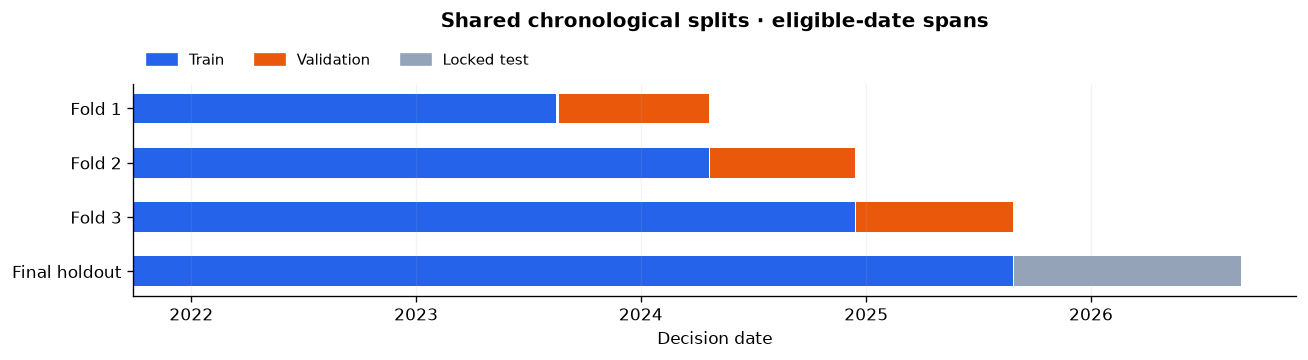

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.1))
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1])]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        left = mdates.date2num(dates.min())
        width = mdates.date2num(dates.max()) - left + 1
        ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · eligible-date spans", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train"), Patch(color=COLORS[1], label="Validation"),
                   Patch(color="#94a3b8", label="Locked test")], loc="lower left", bbox_to_anchor=(0, 1.01),
          ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()

## Training and metrics

Same MLP widths `(64, 32)`, seeds `[42, 123, 2026]`, Adam settings, 200-epoch limit, patience 25, threshold 0.5, and checkpoint rule `(MCC, macro-F1, -log loss)` as Level 1. Fit one text pipeline per fold, shared across classifier seeds. No representation search is performed here.

Center/scale market inputs on train. Scale projected text using news-present train windows without centering; scale availability on all train rows without centering. Zero/padded inputs stay zero. Common classifier initialization matches L1-d. Test remains locked; final refitting, if enabled, learns a fresh text pipeline on development only and uses median selected epochs per seed.

Primary: **MCC**. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin ECE. Fold metrics average individual seeds, without ensembling. Input width is equal, but effective parameter counts differ by representation.

In [5]:
def score_binary(y, probability):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= .5).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up,
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
print("Metric checks passed.")

Metric checks passed.


## Concat and train-only scaling

Input order is `[market, SVD coordinates + zero padding, availability]`. Mean pooling includes zero/OOV article vectors; missing collected news is separate from an unusable lexical vector. Checks enforce common initial classifier arrays and exact-zero empty windows.

In [6]:
class BlockScaler:
    def fit(self, frame):
        self.market = StandardScaler().fit(frame[MARKET_FEATURES])
        news = frame.loc[frame.has_news.eq(1), TEXT_FEATURES]
        if len(news) == 0:
            raise ValueError("This training split has no news; review the corpus/split before fitting a text baseline.")
        self.text = StandardScaler(with_mean=False).fit(news)
        self.availability = StandardScaler(with_mean=False).fit(frame[AVAIL_FEATURES])
        self.mean_ = np.r_[self.market.mean_, np.zeros(len(TEXT_FEATURES) + len(AVAIL_FEATURES))]
        self.scale_ = np.r_[self.market.scale_, self.text.scale_, self.availability.scale_]
        self.n_samples_seen_, self.news_n_samples_seen_ = len(frame), len(news)
        return self

    def transform(self, frame):
        result = (frame[FEATURES].to_numpy(dtype=float) - self.mean_) / self.scale_
        empty = frame.has_news.eq(0).to_numpy()
        assert not result[empty, len(MARKET_FEATURES):].any()
        assert np.isfinite(result).all()
        return result

class MarketAlignedMLP(MLPClassifier):
    def _init_coef(self, fan_in, fan_out, dtype):
        if fan_in != len(FEATURES):
            return super()._init_coef(fan_in, fan_out, dtype)
        market_weights, bias = super()._init_coef(len(MARKET_FEATURES), fan_out, dtype)
        blocks = [market_weights]
        for width, offset in [(len(TEXT_FEATURES), 1000003), (len(AVAIL_FEATURES), 2000003)]:
            rng = check_random_state(int(self.random_state) + offset)
            bound = np.sqrt(6. / (width + fan_out))
            blocks.append(rng.uniform(-bound, bound, (width, fan_out)).astype(dtype))
        return np.vstack(blocks), bias

for seed in SEEDS:
    reference = MLPClassifier(**MLP_CONFIG, random_state=seed)
    extended = MarketAlignedMLP(**MLP_CONFIG, random_state=seed)
    reference._random_state, extended._random_state = check_random_state(seed), check_random_state(seed)
    for old_in, new_in, width in [(len(MARKET_FEATURES), len(FEATURES), 64), (64, 64, 32), (32, 32, 1)]:
        old_weights, old_bias = reference._init_coef(old_in, width, np.float64)
        new_weights, new_bias = extended._init_coef(new_in, width, np.float64)
        assert np.array_equal(old_weights, new_weights[:old_in]) and np.array_equal(old_bias, new_bias)

print("Common classifier initial arrays verified; scaler checks run inside each training fit.")


Common classifier initial arrays verified; scaler checks run inside each training fit.


In [7]:
predictions_list, result_rows, fit_rows, history_rows, snapshots = [], [], [], [], []
text_models = {}

def make_model(seed):
    return MarketAlignedMLP(**MLP_CONFIG, random_state=int(seed))

def train_model(train, validation, seed, run, fixed_epochs=None):
    start = time.perf_counter()
    scaler = BlockScaler().fit(train)
    assert scaler.n_samples_seen_ == len(train)
    assert np.allclose(scaler.market.mean_, train[MARKET_FEATURES].mean().to_numpy())
    assert scaler.news_n_samples_seen_ == train.has_news.sum()
    x_train, y_train = scaler.transform(train), train.y.to_numpy(dtype=int)
    x_val = scaler.transform(validation) if validation is not None else None
    model, best_model, best_key, best_epoch, stale = make_model(seed), None, None, 0, 0
    limit = int(fixed_epochs) if fixed_epochs is not None else MAX_EPOCHS
    with threadpool_limits(limits=1):
        for epoch in range(1, limit + 1):
            model.partial_fit(x_train, y_train, classes=np.array([0, 1]))
            if validation is None:
                continue
            val_probability = model.predict_proba(x_val)[:, 1]
            score = score_binary(validation.y, val_probability)
            train_loss = score_binary(y_train, model.predict_proba(x_train)[:, 1])["log_loss"]
            history_rows.append({"run": run, "seed": seed, "epoch": epoch,
                                 "train_log_loss": train_loss, "val_log_loss": score["log_loss"],
                                 "val_mcc": score["mcc"], "val_macro_f1": score["macro_f1"]})
            key = (score["mcc"], score["macro_f1"], -score["log_loss"])
            if best_key is None or key > best_key:
                best_model, best_key, best_epoch, stale = copy.deepcopy(model), key, epoch, 0
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    if validation is None:
        best_model, best_epoch = model, limit
    return scaler, best_model, best_epoch, epoch, (time.perf_counter() - start) * 1000

def evaluate_run(run, train, evaluation, role, fixed_epoch_by_seed=None):
    representation = FoldTextRepresentation().fit(train)
    text_models[run] = representation
    train = representation.transform(train, "train")
    evaluation = representation.transform(evaluation, role)
    active_indices = np.r_[np.arange(len(MARKET_FEATURES) + representation.rank),
                           np.arange(len(FEATURES) - len(AVAIL_FEATURES), len(FEATURES))]
    active_features = [FEATURES[i] for i in active_indices]
    print(f"{run}: {len(representation.training_ids)} training articles, {representation.fit_shape[1]} terms, rank={representation.rank}")
    for seed in SEEDS:
        fixed_epochs = None if fixed_epoch_by_seed is None else fixed_epoch_by_seed[seed]
        scaler, model, best_epoch, epochs_run, fit_ms = train_model(
            train, evaluation if fixed_epochs is None else None, seed, run, fixed_epochs)
        start = time.perf_counter()
        with threadpool_limits(limits=1):
            probability = model.predict_proba(scaler.transform(evaluation))[:, 1]
        predict_ms = (time.perf_counter() - start) * 1000
        parameter_count = sum(a.size for a in [*model.coefs_, *model.intercepts_])
        scored = score_binary(evaluation.y, probability)
        result_rows.append({"run": run, "role": role, "seed": seed, **scored})
        fit_rows.append({"run": run, "seed": seed, "train_n": len(train), "feature_count": len(active_features), "model_input_width": len(FEATURES), "svd_rank": representation.rank,
                         "train_up": int(train.y.eq(1).sum()), "train_news_days": scaler.news_n_samples_seen_, "best_epoch": best_epoch, "epochs_run": epochs_run,
                         "fit_ms": fit_ms, "predict_ms": predict_ms, "trainable_parameters": parameter_count, "frozen_encoder_parameters": 0, "prediction_effective_parameters": parameter_count - (TEXT_WIDTH - representation.rank) * 64, "learned_text_numeric_parameters": representation.svd.components_.size + representation.vectorizer.idf_.size})
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = evaluation[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = run, role, MODEL_ID, seed
        output["p_up"], output["y_pred"] = probability, (probability >= .5).astype(int)
        predictions_list.append(output)
        # Store prediction-equivalent active-input weights; padding weights are unused.
        active_coefs = [model.coefs_[0][active_indices], *model.coefs_[1:]]
        snapshot = {"run": run, "seed": seed, "features": active_features, "best_epoch": best_epoch,
                    "snapshot_kind": "inference_active_features_only", "full_training_input_width": len(FEATURES),
                    "svd_rank": representation.rank, "text_transform_components_sha256": representation.components_sha,
                    "scaler_mean": scaler.mean_[active_indices].tolist(), "scaler_scale": scaler.scale_[active_indices].tolist(),
                    "scaler_training_rows": scaler.n_samples_seen_, "text_scaler_training_rows": scaler.news_n_samples_seen_,
                    "coefs": [a.tolist() for a in active_coefs], "intercepts": [a.tolist() for a in model.intercepts_],
                    "classes": model.classes_.tolist(), "activation": "relu", "output_activation": "logistic"}
        z = (evaluation[active_features].to_numpy(dtype=float) - scaler.mean_[active_indices]) / scaler.scale_[active_indices]
        for weights, bias in zip(active_coefs[:-1], model.intercepts_[:-1]):
            z = np.maximum(0., z @ weights + bias)
        logits = (z @ active_coefs[-1] + model.intercepts_[-1]).ravel()
        assert np.allclose(1 / (1 + np.exp(-np.clip(logits, -700, 700))), probability)
        snapshots.append(snapshot)
        print(f"{run} seed={seed}: best epoch {best_epoch}, MCC={scored['mcc']:.4f}")

for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    evaluate_run(f"fold_{fold_id}", train, val, "validation")

if RUN_FINAL_TEST:
    fixed_epoch_by_seed = {seed: int(np.median([r["best_epoch"] for r in fit_rows if r["seed"] == seed])) for seed in SEEDS}
    evaluate_run("final_test", final_train, take_rows(final.loc[final.role.eq("test")]), "test", fixed_epoch_by_seed)

predictions = pd.concat(predictions_list, ignore_index=True)
seed_results, fits, history = pd.DataFrame(result_rows), pd.DataFrame(fit_rows), pd.DataFrame(history_rows)
assert not predictions.duplicated(["role", "training_seed", "Date"]).any()
for seed in SEEDS:
    assert len(predictions.loc[predictions.role.eq("validation") & predictions.training_seed.eq(seed)]) == len(seen_validation_dates)
numeric = [c for c in seed_results.select_dtypes(include="number") if c != "seed"]
results = seed_results.groupby(["run", "role"], sort=False)[numeric].mean().reset_index()
for field in ["n", "n_down", "n_up"]:
    results[field] = results[field].astype(int)
seed_std = seed_results.groupby("run", sort=False)[METRICS].std(ddof=1)
validation_results = results.loc[results.role.eq("validation"), METRICS]
display(fits.round(3))
display(seed_results[["run", "seed", "n", *METRICS]].round(4))
display(results[["run", "role", "n", *METRICS]].round(4))
display(seed_std.rename_axis("run").round(4))
display(pd.DataFrame({"mean_validation": validation_results.mean(),
                      "std_across_folds": validation_results.std(ddof=1)}).round(4))
print("n counts unique dates; fold metrics average individual-seed scores, without ensembling.")
print("Final test scored." if RUN_FINAL_TEST else "Final-test scoring remains locked.")
text_fit_rows = []
for run, representation in text_models.items():
    evaluation_role = "test" if run == "final_test" else "validation"
    coverage = representation.coverage[evaluation_role]
    text_fit_rows.append({"run": run, "training_articles": len(representation.training_ids),
                          "vocabulary_size": representation.fit_shape[1], "svd_rank": representation.rank,
                          "explained_variance": float(representation.svd.explained_variance_ratio_.sum()),
                          "evaluation_articles": coverage["articles"], "unigram_oov_rate": coverage["oov_unigram_rate"],
                          "zero_tfidf_articles": coverage["zero_tfidf_articles"], "text_fit_seconds": representation.fit_seconds})
text_fit_summary = pd.DataFrame(text_fit_rows)
display(text_fit_summary.round(4))


fold_1: 190 training articles, 7355 terms, rank=128


fold_1 seed=42: best epoch 1, MCC=0.0580


fold_1 seed=123: best epoch 3, MCC=0.0872


fold_1 seed=2026: best epoch 8, MCC=0.0691


fold_2: 228 training articles, 8559 terms, rank=128


fold_2 seed=42: best epoch 4, MCC=0.1210


... (9 outputs left out)

,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
run,,,,,,,,
fold_1,0.0147,0.0083,0.0066,0.0097,0.0044,0.0042,0.0144,0.0214
fold_2,0.0504,0.0591,0.0305,0.0288,0.0314,0.0120,0.0487,0.0405
fold_3,0.0077,0.0055,0.0037,0.0037,0.0036,0.0131,0.0375,0.0395


,mean_validation,std_across_folds
mcc,0.0926,0.0598
macro_f1,0.5189,0.0164
balanced_accuracy,0.5404,0.0239
accuracy,0.5551,0.0294
roc_auc,0.5439,0.0106
brier,0.2599,0.0133
log_loss,0.7306,0.0456
ece_10,0.0991,0.0341


n counts unique dates; fold metrics average individual-seed scores, without ensembling.
Final-test scoring remains locked.


,run,training_articles,vocabulary_size,svd_rank,explained_variance,evaluation_articles,unigram_oov_rate,zero_tfidf_articles,text_fit_seconds
0,fold_1,190,7355,128,0.8336,38,0.2010,0,0.2837
1,fold_2,228,8559,128,0.7357,37,0.1522,0,0.2629
2,fold_3,265,9640,128,0.6602,43,0.1414,0,0.2836


## Text diagnostics

Variance is measured on training articles. OOV is the evaluation unigram-token rate under that fold's vocabulary; zero TF-IDF articles remain in their original windows.


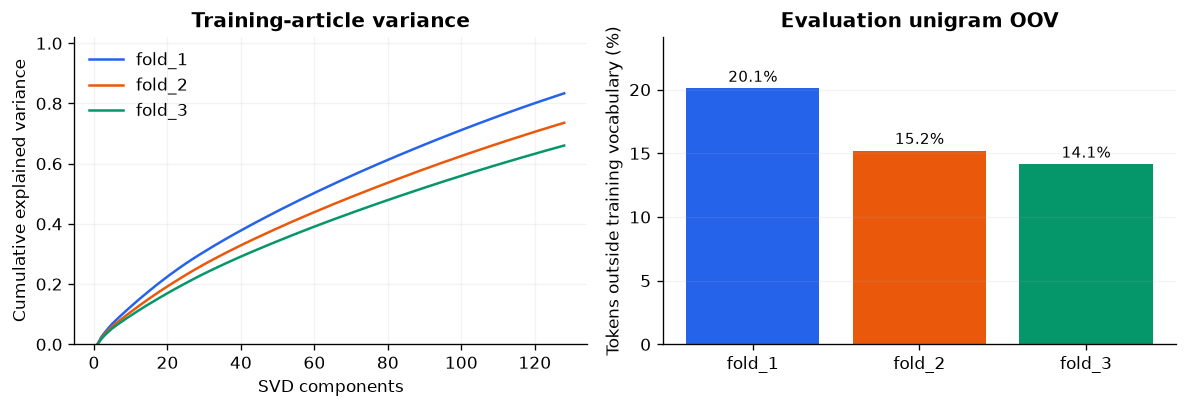

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for index, (run, representation) in enumerate(text_models.items()):
    axes[0].plot(np.arange(1, representation.rank + 1), np.cumsum(representation.svd.explained_variance_ratio_),
                 color=COLORS[index % 3], label=run)
axes[0].set(xlabel="SVD components", ylabel="Cumulative explained variance", ylim=(0, 1.02), title="Training-article variance")
axes[0].legend(frameon=False)
axes[0].grid(alpha=.15)
values = text_fit_summary.unigram_oov_rate.to_numpy(dtype=float) * 100
axes[1].bar(text_fit_summary.run, values, color=[COLORS[i % 3] for i in range(len(values))])
for index, value in enumerate(values):
    axes[1].annotate(f"{value:.1f}%", (index, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
axes[1].set(title="Evaluation unigram OOV", ylabel="Tokens outside training vocabulary (%)", ylim=(0, max(float(values.max()) * 1.2, 1)))
axes[1].grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Sampling uncertainty

95% intervals use 1,000 circular moving-block resamples of 10 evaluated observations. Reuse each fold's seed (`20261110 + run index`) and sampled dates across all training seeds. Average seed scores within each resample. These intervals condition on the fitted checkpoints; seed standard deviations are reported separately. Block settings and date order match L1-a/L1-b.

In [9]:
def block_intervals(frame, seed):
    reference = frame.loc[frame.training_seed.eq(SEEDS[0])].sort_values("Date")
    y = reference.y.to_numpy(dtype=int)
    probabilities = []
    for training_seed in SEEDS:
        rows = frame.loc[frame.training_seed.eq(training_seed)].sort_values("Date")
        assert rows.Date.tolist() == reference.Date.tolist() and rows.y.tolist() == reference.y.tolist()
        probabilities.append(rows.p_up.to_numpy(dtype=float))
    n, rng = len(y), np.random.default_rng(seed)
    length = min(BLOCK_LENGTH, n)
    sampled = {metric: [] for metric in METRICS}
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        scores = [score_binary(y[positions], p[positions]) for p in probabilities]
        for metric in METRICS:
            values = [r[metric] for r in scores]
            sampled[metric].append(float(np.mean(values)))
    output = []
    for metric, values in sampled.items():
        valid = np.asarray(values, dtype=float)
        valid = valid[np.isfinite(valid)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        output.append({"metric": metric, "low_95": float(low), "high_95": float(high), "valid_resamples": len(valid)})
    return output

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))

,run,metric,low_95,high_95,valid_resamples
0,fold_1,mcc,-0.0092,0.1604,1000
1,fold_1,macro_f1,0.4849,0.5692,1000
2,fold_1,balanced_accuracy,0.4959,0.5739,1000
3,fold_1,accuracy,0.5211,0.6245,1000
8,fold_2,mcc,0.0486,0.2667,1000
9,fold_2,macro_f1,0.4682,0.5864,1000
10,fold_2,balanced_accuracy,0.5201,0.6126,1000
11,fold_2,accuracy,0.5073,0.6352,1000
16,fold_3,mcc,-0.0765,0.1727,1000
17,fold_3,macro_f1,0.4378,0.5610,1000


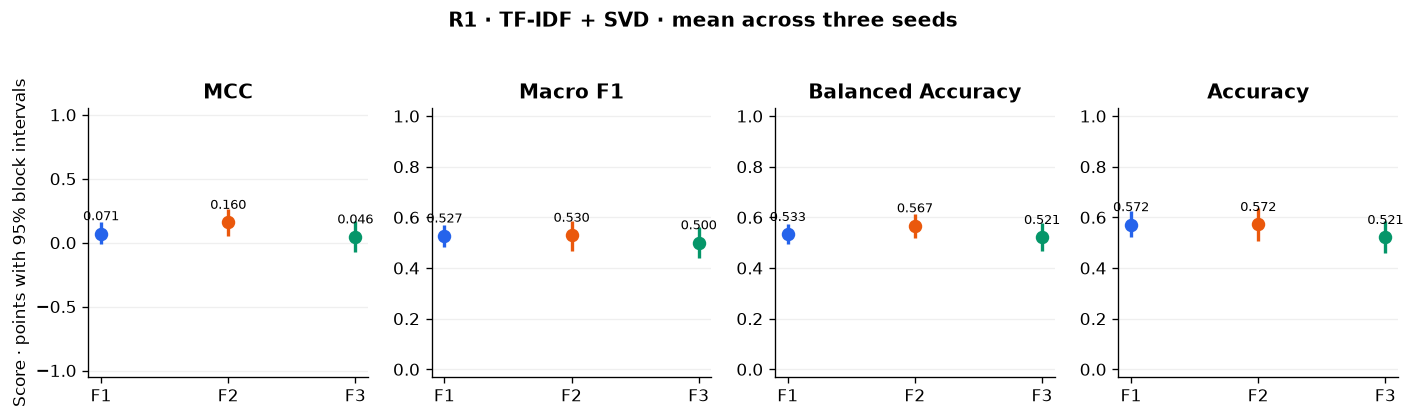

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("R1 · TF-IDF + SVD · mean across three seeds", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()

## Training curves

Solid = validation log loss; dashed = training log loss. Checkpoints are selected by MCC, then macro-F1, then log loss.


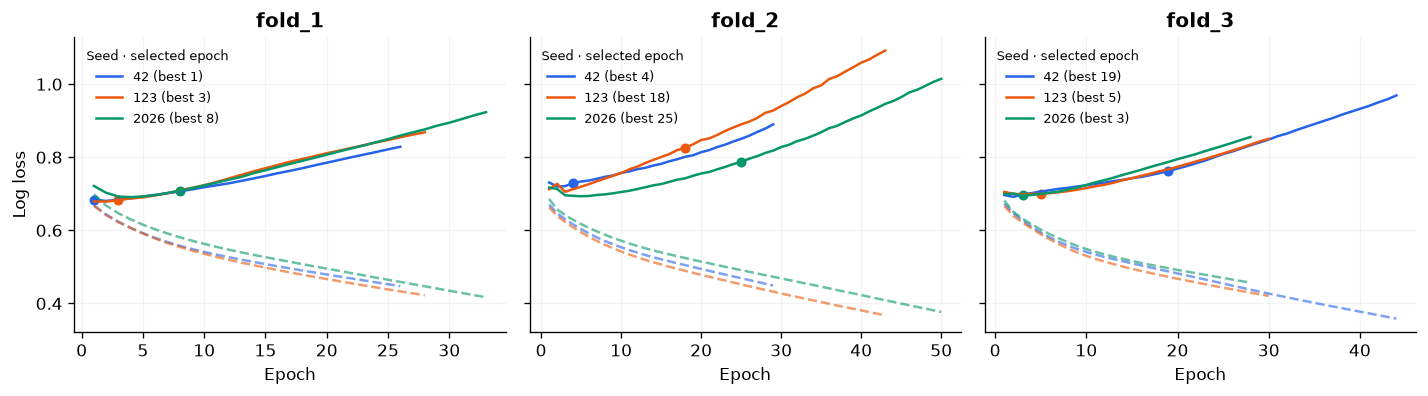

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, run in zip(axes, [f"fold_{i}" for i in sorted(folds.fold.unique())]):
    for index, seed in enumerate(SEEDS):
        curve = history.loc[history.run.eq(run) & history.seed.eq(seed)]
        best_epoch = int(fits.loc[fits.run.eq(run) & fits.seed.eq(seed), "best_epoch"].iloc[0])
        ax.plot(curve.epoch, curve.val_log_loss, color=COLORS[index], label=f"{seed} (best {best_epoch})")
        ax.plot(curve.epoch, curve.train_log_loss, "--", color=COLORS[index], alpha=.6)
        selected = curve.loc[curve.epoch.eq(best_epoch)].iloc[0]
        ax.scatter([best_epoch], [selected.val_log_loss], s=25, color=COLORS[index])
    ax.set(title=run, xlabel="Epoch")
    ax.grid(alpha=.15)
    ax.legend(title="Seed · selected epoch", fontsize=8, title_fontsize=8, frameon=False)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
plt.show()

## Classes, confusion, and probability quality

Confusion annotations are mean counts across three seeds and row percentages. Each fold still has the same unique evaluation dates. Per-class metrics are seed means. Calibration pools seed predictions within bins, so its counts include repeated dates; it is not an ensemble or an independent-sample count.

,run,class,support,precision,recall,f1
0,fold_1,DOWN,64,0.4605,0.3281,0.3820
1,fold_1,UP,94,0.6173,0.7376,0.6717
2,fold_2,DOWN,78,0.6395,0.2949,0.3932
3,fold_2,UP,81,0.5547,0.8395,0.6665
4,fold_3,DOWN,79,0.5356,0.3165,0.3978
5,fold_3,UP,79,0.5150,0.7257,0.6024


,run,bin,prediction_entries,unique_dates,predicted_up,observed_up
0,fold_1,3,3,3,0.3712,0.6667
1,fold_1,4,134,86,0.4701,0.5373
2,fold_1,5,215,125,0.5460,0.6047
3,fold_1,6,90,67,0.6408,0.6667
4,fold_1,7,24,21,0.7535,0.5833
5,fold_1,8,4,4,0.8608,0.7500
6,fold_1,9,4,3,0.9350,0.2500
7,fold_2,1,4,4,0.1673,0.0000
8,fold_2,2,8,8,0.2480,0.1250
9,fold_2,3,26,22,0.3520,0.5000


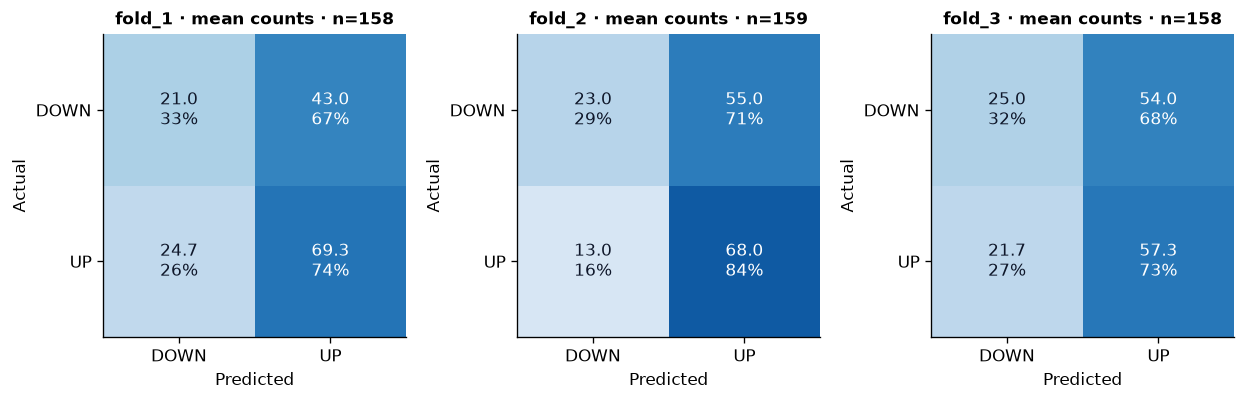

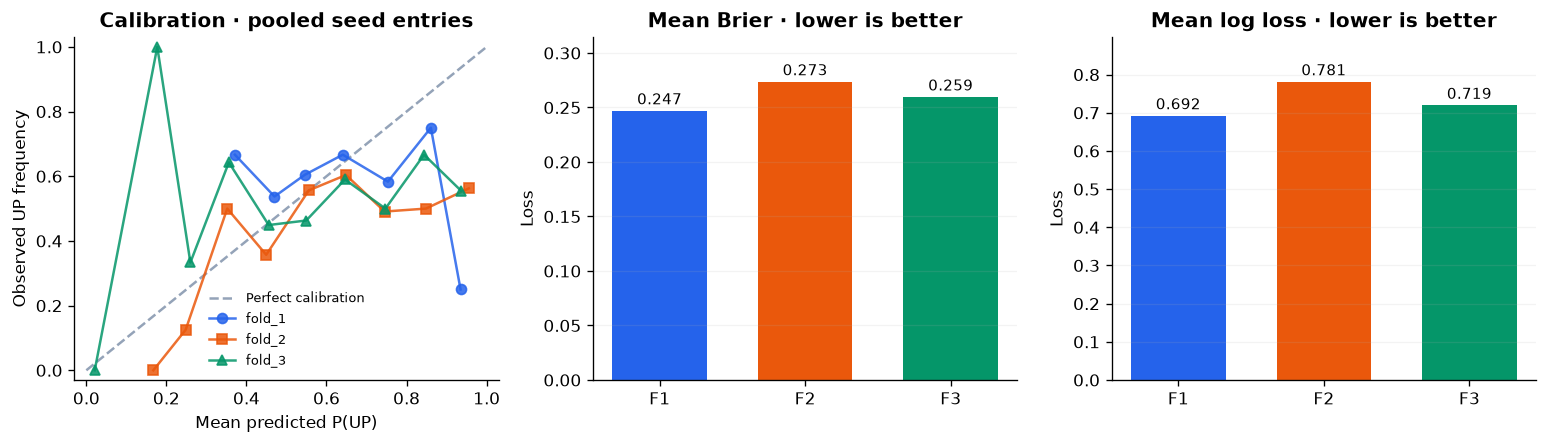

In [12]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"], "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "prediction_entries": len(group),
                                 "unique_dates": group.Date.nunique(), "predicted_up": float(group.p_up.mean()),
                                 "observed_up": float(group.y.mean())})
per_class, calibration = pd.DataFrame(class_rows), pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]:.1f}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · mean counts · n={row['n']}", fontsize=10)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=run)
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)",
            ylabel="Observed UP frequency", title="Calibration · pooled seed entries")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Mean Brier · lower is better"),
                           (axes[2], "log_loss", "Mean log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Coverage and subgroup checks

Retain all eligible dates, including empty-news windows. Subgroup sizes count unique dates; scores average individual seeds. Weekday/gap groups use the target endpoint. Inspect small subsets cautiously.

,run,group,n,mcc,macro_f1,balanced_accuracy,accuracy
0,fold_1,all,158,0.0714,0.5269,0.5329,0.5717
1,fold_1,news_present,21,-0.0929,0.3880,0.4722,0.5238
2,fold_1,empty,137,0.0935,0.5397,0.5436,0.5791
3,fold_1,singleton,13,-0.1376,0.3787,0.4500,0.5385
4,fold_1,multi_article,8,0.0000,0.3889,0.5000,0.5000
5,fold_1,target_Monday,30,-0.1531,0.3803,0.4600,0.5111
6,fold_1,target_other_weekday,128,0.1120,0.5508,0.5532,0.5859
7,fold_1,target_gap_1d,122,0.1131,0.5515,0.5538,0.5874
8,fold_1,target_gap_3d,28,-0.1356,0.3881,0.4688,0.5238
9,fold_1,target_gap_other,8,0.0399,0.4651,0.5000,0.5000


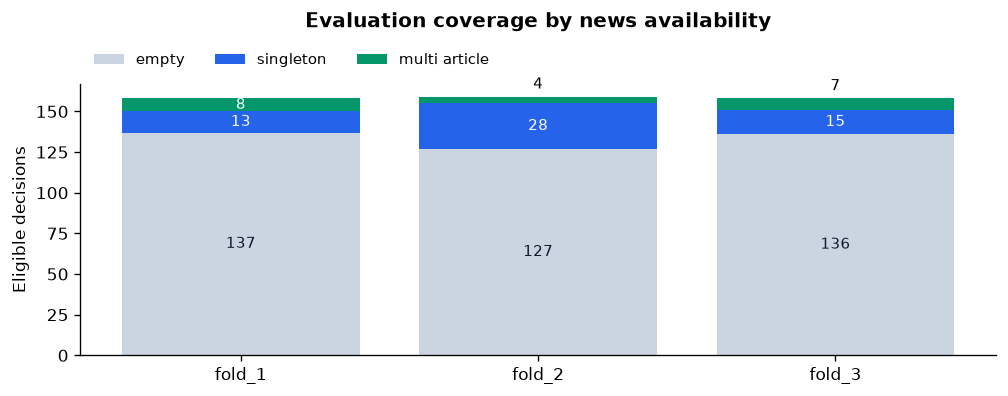

In [13]:
subgroup_rows = []
for run, all_seeds in predictions.groupby("run", sort=False):
    frame = all_seeds.loc[all_seeds.training_seed.eq(SEEDS[0])].sort_values("Date")
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0), "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        dates = frame.loc[mask, "Date"]
        selected = all_seeds.loc[all_seeds.Date.isin(dates)]
        if len(dates):
            scores = pd.DataFrame([score_binary(g.y, g.p_up) for _, g in selected.groupby("training_seed")]).mean().to_dict()
        else:
            scores = {m: np.nan for m in METRICS}
        subgroup_rows.append({"run": run, "group": name, **scores, "n": len(dates)})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Result bundle

Metrics, intervals, predictions, classifier snapshots, training-article IDs, text coverage, and vocabulary/IDF/SVD fingerprints are embedded below. Zero-only weights are omitted from inference snapshots. Fitted text transformers remain in memory; Run All recreates them from recorded inputs/settings. No sidecar files are written. Select neither the representation nor a filter using test scores.

In [14]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json", "aligned_articles.jsonl", "news_windows.jsonl"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "tfidf_svd", "level": 2, "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST, "hard_prediction_rule": "P(UP) >= 0.5; threshold fixed",
    "probability_rule": "MLP logistic output; no calibration fitted",
    "input_predictors": FEATURES, "excluded_predictors": ["future outcomes", "sentiment labels", "legacy aligned dates", "collection tags"],
    "macro_inputs": [], "training_seeds": SEEDS, "threshold_tuned": False,
    "model": MLP_CONFIG, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "selection": ["validation MCC", "validation macro-F1", "negative validation log loss"],
    "scaler_fit": "Market: centered train; text: uncentered news-present train; availability: uncentered all train",
    "feature_blocks": {"market": MARKET_FEATURES, "text": TEXT_FEATURES, "availability": AVAIL_FEATURES},
    "shared_initialization": "Market rows and common hidden/output layers match L1-c; extra blocks use independent seeded Glorot",
    "text_pipeline": {"tfidf": TFIDF_CONFIG, "tokenizer": "str.split on prepared static tokens",
                      "svd": SVD_CONFIG, "requested_svd_rank": SVD_DIM, "common_text_width": TEXT_WIDTH},
    "level_3_eligible": False,
    "representation_fits": [representation.provenance(run) for run, representation in text_models.items()],
    "fusion": "concatenation; no query/cross-attention/gate",
    "article_window_aggregation": "training-fitted article TF-IDF/SVD, then uniform article mean; empty windows zero",
    "availability_transform": ["log1p(n_berita)", "has_news"], "final_epochs": "Per-seed median best epoch across development folds",
    "trainable_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "prediction_effective_parameters_per_fit": sorted(fits.prediction_effective_parameters.unique().tolist()),
    "score_aggregation": "Mean individual-seed scores within fold, then equal-weight mean across validation folds; no ensemble",
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "same_sampled_dates_across_training_seeds": True, "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"], "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
def to_records(frame):
    def clean(value):
        if isinstance(value, (pd.Timestamp, datetime)):
            return value.isoformat()
        if isinstance(value, np.generic):
            return clean(value.item())
        return None if pd.isna(value) else value
    return [{key: clean(value) for key, value in row.items()} for row in frame.to_dict("records")]
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "seed_metrics": to_records(seed_results), "seed_std": to_records(seed_std.reset_index()),
                 "validation_summary": to_records(validation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "intervals": to_records(intervals), "per_class": to_records(per_class), "calibration": to_records(calibration),
                 "subgroups": to_records(subgroups), "predictions": to_records(predictions),
                 "history": to_records(history), "selected_models": snapshots, "text_fit_summary": to_records(text_fit_summary)}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Stored {len(predictions)} seed-specific predictions across {predictions.Date.nunique()} dates; final test evaluated: {RUN_FINAL_TEST}.")

Stored 1425 seed-specific predictions across 475 dates; final test evaluated: False.
